In [ ]:
#Step 1 - Import necessary libraries
import pandas as pd
import numpy as np
from scipy.stats.mstats import winsorize
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
#Step 2 - Mount Google Drive and replace the paths with the actual paths to your CSV files in Google Drive

from google.colab import drive
drive.mount('/content/drive')

transaction_path = '/content/drive/MyDrive/Data Mining Principles/FinMark datasets/Transaction_Data.csv'
productoffering_path = '/content/drive/MyDrive/Data Mining Principles/FinMark datasets/Product_Offering_Data.csv'
customerfeedback_path = '/content/drive/MyDrive/Data Mining Principles/FinMark datasets/Customer_Feedback_Data.csv'

# Load the datasets
transaction_df = pd.read_csv(transaction_path)
productoffering_df = pd.read_csv(productoffering_path)
customerfeedback_df = pd.read_csv(customerfeedback_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Step 3 - Basic Dataset Overview

# --- Total number of rows (excluding header) ---
total_rows = len(transaction_df)
print(f"\nTotal number of rows in Transaction_Data dataset (excluding header): {total_rows}")

total_rows = len(productoffering_df)
print(f"\nTotal number of rows in Product_Offering_Data dataset (excluding header): {total_rows}")

total_rows = len(customerfeedback_df)
print(f"\nTotal number of rows in Customer_Feedback_Data dataset (excluding header): {total_rows}")

# --- Total number of columns ---
total_columns = transaction_df.shape[1]
print(f"Total number of columns in Transaction_Data dataset: {total_columns}")

total_columns = productoffering_df.shape[1]
print(f"Total number of columns in Product_Offering_Data dataset: {total_columns}")

total_columns = customerfeedback_df.shape[1]
print(f"Total number of columns in Customer_Feedback_Data dataset: {total_columns}")


Total number of rows in Transaction_Data dataset (excluding header): 5050

Total number of rows in Product_Offering_Data dataset (excluding header): 15

Total number of rows in Customer_Feedback_Data dataset (excluding header): 5050
Total number of columns in Transaction_Data dataset: 5
Total number of columns in Product_Offering_Data dataset: 6
Total number of columns in Customer_Feedback_Data dataset: 4


In [ ]:
#Step 4 - Check datasets info
print("\nTransaction Data Info:")
transaction_df.info()

print("\nProduct Offering Data Info:")
productoffering_df.info()

print("\nCustomer Feedback Data Info:")
customerfeedback_df.info()


Transaction Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      5050 non-null   int64  
 1   Customer_ID         5050 non-null   int64  
 2   Transaction_Date    5050 non-null   object 
 3   Transaction_Amount  4950 non-null   float64
 4   Transaction_Type    5050 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 197.4+ KB

Product Offering Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Product_ID           15 non-null     int64  
 1   Product_Name         15 non-null     object 
 2   Product_Type         15 non-null     object 
 3   Risk_Level           15 non-null     object 
 4   Target_Age_Group     0 non-

Data Preprocessing

In [ ]:
#Step 5 - Check and remove duplicates

# -------------------------------
# Transaction_Data
# -------------------------------
# --- 1. Number of unique Transaction IDs ---
unique_txn_ids = transaction_df['Transaction_ID'].nunique()
print(f"Number of unique Transaction_IDs: {unique_txn_ids}")

# --- 2. Count duplicate Transaction IDs ---
duplicate_txn_count = transaction_df.duplicated(subset=['Transaction_ID']).sum()
print(f"Number of duplicate Transaction_ID entries: {duplicate_txn_count}")

# --- 3. View the duplicate records ---
duplicate_transactions = transaction_df[
    transaction_df.duplicated(subset=['Transaction_ID'], keep=False)
].sort_values(by='Transaction_ID')

display(duplicate_transactions)

# --- 4. Drop duplicate Transaction_ID rows (keep first occurrence) ---
transaction_df = transaction_df.drop_duplicates(subset=['Transaction_ID'])

# --- 5. Re-check counts after dropping duplicates ---
unique_txn_ids_after = transaction_df['Transaction_ID'].nunique()
print(f"Number of unique Transaction_IDs after dropping duplicates: {unique_txn_ids_after}")

duplicate_txn_count_after = transaction_df.duplicated(subset=['Transaction_ID']).sum()
print(f"Number of duplicate Transaction_ID entries after dropping duplicates: {duplicate_txn_count_after}")

# --- 6. Confirm total row count ---
print(f"Total rows in Transaction_Data after dropping duplicates: {len(transaction_df)}")


# -------------------------------
# Product Offering Data
# -------------------------------
# --- 1. Check & Remove Full Row Duplicates ---
full_row_duplicates = productoffering_df.duplicated().sum()
print(f"Number of full-row duplicate rows in Product Offering: {full_row_duplicates}")

# --- 2. Remove full-row duplicates ---
productoffering_df = productoffering_df.drop_duplicates()

# --- 3. Verify cleanup ---
print(f"Rows after removing duplicates in Product Offering: {len(productoffering_df)}")

# -------------------------------
# Customer Feedback Data
# -------------------------------
# --- 1. Check & Remove Full Row Duplicates ---
full_row_duplicates = customerfeedback_df.duplicated().sum()
print(f"Number of full-row duplicate rows in Customer Feedback: {full_row_duplicates}")

# --- 2. Remove full-row duplicates ---
customerfeedback_df = customerfeedback_df.drop_duplicates()

# --- 3. Verify cleanup ---
print(f"Rows after removing duplicates in Customer Feedback: {len(customerfeedback_df)}")

Number of unique Transaction_IDs: 5000
Number of duplicate Transaction_ID entries: 50


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
56,57,142,2023-01-03 08:00:00,3791.0,Purchase
5019,57,142,2023-01-03 08:00:00,3791.0,Purchase
5021,145,456,2023-01-07 00:00:00,4527.0,Loan Payment
144,145,456,2023-01-07 00:00:00,4527.0,Loan Payment
155,156,474,2023-01-07 11:00:00,1164.0,Loan Payment
...,...,...,...,...,...
5008,4558,992,2023-07-09 21:00:00,532.0,Bill Payment
4741,4742,757,2023-07-17 13:00:00,386.0,Investment
5033,4742,757,2023-07-17 13:00:00,386.0,Investment
5001,4971,463,2023-07-27 02:00:00,3123.0,Loan Payment


Number of unique Transaction_IDs after dropping duplicates: 5000
Number of duplicate Transaction_ID entries after dropping duplicates: 0
Total rows in Transaction_Data after dropping duplicates: 5000
Number of full-row duplicate rows in Product Offering: 5
Rows after removing duplicates in Product Offering: 10
Number of full-row duplicate rows in Customer Feedback: 81
Rows after removing duplicates in Customer Feedback: 4969


In [ ]:
#Step 6 - Merge Transaction and Customer Feedback Data using Customer_ID
# Separate the transaction and feedback datasets
transaction_only = transaction_df.copy()
feedback_only = customerfeedback_df.copy()

# Add missing columns so both DataFrames have the same columns
transaction_only['Satisfaction_Score'] = np.nan
transaction_only['Feedback_Comments'] = np.nan
transaction_only['Likelihood_to_Recommend'] = np.nan

feedback_only['Transaction_ID'] = np.nan
feedback_only['Transaction_Date'] = pd.NaT
feedback_only['Transaction_Amount'] = np.nan
feedback_only['Transaction_Type'] = np.nan

# Add Row_Type to help sort later
transaction_only['Row_Type'] = 'Transaction'
feedback_only['Row_Type'] = 'Feedback'

# Ensure columns are in the same order
columns_order = [
    "Customer_ID",
    "Transaction_ID",
    "Transaction_Date",
    "Transaction_Amount",
    "Transaction_Type",
    "Satisfaction_Score",
    "Feedback_Comments",
    "Likelihood_to_Recommend",
    "Row_Type"
]

transaction_only = transaction_only[columns_order]
feedback_only = feedback_only[columns_order]

# --- Concatenate transactions and feedback vertically ---
stacked_df = pd.concat([transaction_only, feedback_only], ignore_index=True)

# --- Correct sorting: transactions first, feedback after, per customer ---
# Add numeric helper column for Row_Type
stacked_df['Row_Type_Num'] = stacked_df['Row_Type'].map({'Transaction': 0, 'Feedback': 1})

# Sort by Customer_ID, then Row_Type_Num
stacked_df = stacked_df.sort_values(
    by=['Customer_ID', 'Row_Type_Num'],
    kind='stable'  # preserves original order within transactions/feedback
).drop(columns=['Row_Type', 'Row_Type_Num']).reset_index(drop=True)

# --- Preview nicely ---
from IPython.display import display
display(stacked_df.head(15))

# --- Dataset info ---
print("\nMerged Dataset Info:")
stacked_df.info()

,Customer_ID,Transaction_ID,Transaction_Date,Transaction_Amount,Transaction_Type,Satisfaction_Score,Feedback_Comments,Likelihood_to_Recommend
0,1,29.0,2023-01-02 04:00:00,156.0,Loan Payment,NaN,NaN,NaN
1,1,282.0,2023-01-12 17:00:00,1572.0,Bill Payment,NaN,NaN,NaN
2,1,2883.0,2023-05-01 02:00:00,4867.0,Bill Payment,NaN,NaN,NaN
3,1,3135.0,2023-05-11 14:00:00,1278.0,Investment,NaN,NaN,NaN
4,1,3626.0,2023-06-01 01:00:00,3970.0,Purchase,NaN,NaN,NaN
5,1,4372.0,2023-07-02 03:00:00,4993.0,Bill Payment,NaN,NaN,NaN
6,1,NaN,NaN,NaN,NaN,10.0,Very satisfied,9.0
7,1,NaN,NaN,NaN,NaN,7.0,Good service,9.0
8,2,869.0,2023-02-06 04:00:00,2057.0,Bill Payment,NaN,NaN,NaN
9,2,3384.0,2023-05-21 23:00:00,2850.0,Loan Payment,NaN,NaN,NaN



Merged Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9969 entries, 0 to 9968
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer_ID              9969 non-null   int64  
 1   Transaction_ID           5000 non-null   float64
 2   Transaction_Date         5000 non-null   object 
 3   Transaction_Amount       4900 non-null   float64
 4   Transaction_Type         5000 non-null   object 
 5   Satisfaction_Score       4869 non-null   float64
 6   Feedback_Comments        4969 non-null   object 
 7   Likelihood_to_Recommend  4969 non-null   float64
dtypes: float64(4), int64(1), object(3)
memory usage: 623.2+ KB


In [ ]:
#Step 7: Correct Data Types in stacked_df
# NOTE: - Integer columns that can have missing values use pandas' nullable Int64 type to avoid errors with NaNs.
#       - Transaction_Date is converted to datetime to enable time-based operations (sorting, filtering, grouping).
#       - Transaction_Amount remains float to accommodate cents/decimal values.
#       - Customer_ID is int because it has no missing values.
#       - Proper data types prevent unexpected errors in aggregation, plotting, or further processing.

# Ensure numeric columns are numeric first (coerce errors to NaN)
numeric_cols = ['Transaction_ID', 'Satisfaction_Score', 'Likelihood_to_Recommend', 'Transaction_Amount']
for col in numeric_cols:
    stacked_df[col] = pd.to_numeric(stacked_df[col], errors='coerce')

# Convert integer-like columns to nullable integer (Int64) safely
# Only integer-like values will remain, NaN is allowed
int_cols = ['Transaction_ID', 'Satisfaction_Score', 'Likelihood_to_Recommend']
for col in int_cols:
    # Round floats to nearest int first, then convert to Int64
    stacked_df[col] = stacked_df[col].round().astype('Int64')

# Transaction_Amount remains float
stacked_df['Transaction_Amount'] = stacked_df['Transaction_Amount'].astype(float)

# Convert Transaction_Date to datetime safely
stacked_df['Transaction_Date'] = pd.to_datetime(stacked_df['Transaction_Date'], errors='coerce')

# Transaction_Type and Feedback_Comments remain as object/string

# 6️⃣ Verify changes
print("=== Stacked Dataset Info After Type Correction ===")
stacked_df.info()
display(stacked_df.head(10))

=== Stacked Dataset Info After Type Correction ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9969 entries, 0 to 9968
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Customer_ID              9969 non-null   int64         
 1   Transaction_ID           5000 non-null   Int64         
 2   Transaction_Date         5000 non-null   datetime64[ns]
 3   Transaction_Amount       4900 non-null   float64       
 4   Transaction_Type         5000 non-null   object        
 5   Satisfaction_Score       4869 non-null   Int64         
 6   Feedback_Comments        4969 non-null   object        
 7   Likelihood_to_Recommend  4969 non-null   Int64         
dtypes: Int64(3), datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 652.4+ KB


,Customer_ID,Transaction_ID,Transaction_Date,Transaction_Amount,Transaction_Type,Satisfaction_Score,Feedback_Comments,Likelihood_to_Recommend
0,1,29,2023-01-02 04:00:00,156.0,Loan Payment,<NA>,NaN,<NA>
1,1,282,2023-01-12 17:00:00,1572.0,Bill Payment,<NA>,NaN,<NA>
2,1,2883,2023-05-01 02:00:00,4867.0,Bill Payment,<NA>,NaN,<NA>
3,1,3135,2023-05-11 14:00:00,1278.0,Investment,<NA>,NaN,<NA>
4,1,3626,2023-06-01 01:00:00,3970.0,Purchase,<NA>,NaN,<NA>
5,1,4372,2023-07-02 03:00:00,4993.0,Bill Payment,<NA>,NaN,<NA>
6,1,<NA>,NaT,NaN,NaN,10,Very satisfied,9
7,1,<NA>,NaT,NaN,NaN,7,Good service,9
8,2,869,2023-02-06 04:00:00,2057.0,Bill Payment,<NA>,NaN,<NA>
9,2,3384,2023-05-21 23:00:00,2850.0,Loan Payment,<NA>,NaN,<NA>


In [ ]:
#Step 8: Count missing values per column

# --- Count missing values in stacked_df per relevant row type ---
# Transaction rows: Transaction_ID is not NaN
transaction_rows = stacked_df[stacked_df['Transaction_ID'].notna()]
missing_transaction = transaction_rows[['Transaction_ID', 'Transaction_Date', 'Transaction_Amount', 'Transaction_Type']].isna().sum()
print("Missing values in Transaction rows:")
print(missing_transaction)

# Feedback rows: Transaction_ID is NaN (because these rows have only feedback info)
feedback_rows = stacked_df[stacked_df['Transaction_ID'].isna()]
missing_feedback = feedback_rows[['Satisfaction_Score', 'Feedback_Comments', 'Likelihood_to_Recommend']].isna().sum()
print("\nMissing values in Feedback rows:")
print(missing_feedback)

# --- For productoffering_df ---
print("\nMissing values in productoffering_df:")
missing_product = productoffering_df.isna().sum()
print(missing_product)

Missing values in Transaction rows:
Transaction_ID          0
Transaction_Date        0
Transaction_Amount    100
Transaction_Type        0
dtype: int64

Missing values in Feedback rows:
Satisfaction_Score         100
Feedback_Comments            0
Likelihood_to_Recommend      0
dtype: int64

Missing values in productoffering_df:
Product_ID              0
Product_Name            0
Product_Type            0
Risk_Level              0
Target_Age_Group       10
Target_Income_Group     0
dtype: int64


In [ ]:
#Step 9 - Drop Target_Age_Group column from Product_Offering_Data dataset

# --- 1. Check columns before dropping ---
print("Columns before dropping Target_Age_Group:")
print(productoffering_df.columns)

# --- 2. Drop the column ---
productoffering_df = productoffering_df.drop(columns=['Target_Age_Group'])

# --- 3. Check columns after dropping ---
print("\nColumns after dropping Target_Age_Group:")
print(productoffering_df.columns)

Columns before dropping Target_Age_Group:
Index(['Product_ID', 'Product_Name', 'Product_Type', 'Risk_Level',
       'Target_Age_Group', 'Target_Income_Group'],
      dtype='object')

Columns after dropping Target_Age_Group:
Index(['Product_ID', 'Product_Name', 'Product_Type', 'Risk_Level',
       'Target_Income_Group'],
      dtype='object')


In [ ]:
#Step 10 - Impute missing Satisfaction_Score by Customer_ID
# Missing Satisfaction_Score values in feedback rows are imputed using the median score of the corresponding customer.
# This approach preserves individual customer feedback patterns and prevents bias that could arise from using the overall median across all customers.

# --- Keep a copy before imputation ---
stacked_df_before = stacked_df.copy()

# Identify feedback rows
feedback_rows = stacked_df['Transaction_ID'].isna()

# Compute customer-wise median
customer_median = stacked_df.loc[feedback_rows].groupby('Customer_ID')['Satisfaction_Score']\
    .transform('median')\
    .round(0).astype('Int64')  # round off in case of .5

# Fill missing values
stacked_df.loc[feedback_rows, 'Satisfaction_Score'] = stacked_df.loc[feedback_rows, 'Satisfaction_Score']\
    .fillna(customer_median)

# --- Count missing values after imputation ---
missing_after = stacked_df.loc[feedback_rows, 'Satisfaction_Score'].isna().sum()

# --- Count of rows that were actually imputed ---
imputed_count = feedback_rows & stacked_df_before['Satisfaction_Score'].isna() & stacked_df['Satisfaction_Score'].notna()
num_imputed = imputed_count.sum()

# --- Print both counts in one line ---
print(f"Missing Satisfaction_Score in feedback rows after customer-wise imputation: {missing_after}, Number of rows imputed: {num_imputed}")

# --- Preview only imputed rows ---
imputed_rows = feedback_rows & stacked_df_before['Satisfaction_Score'].isna() & stacked_df['Satisfaction_Score'].notna()

# Select a few random imputed rows for preview
sample_imputed = stacked_df.loc[imputed_rows].sample(5, random_state=42)[
    ['Customer_ID', 'Satisfaction_Score', 'Feedback_Comments']
]

# Display
display(sample_imputed)

Missing Satisfaction_Score in feedback rows after customer-wise imputation: 0, Number of rows imputed: 100


,Customer_ID,Satisfaction_Score,Feedback_Comments
8898,897,4,Good service
5757,581,7,Excellent
7930,804,8,Needs improvement
5192,525,5,Excellent
5162,522,6,Good service


In [ ]:
#Step 11: Impute missing Transaction_Amount by Customer_ID
  #  Missing Transaction_Amount values were imputed using the median transaction amount of the corresponding customer.
  #  This approach preserves individual customer behavior and prevents bias that could arise from using the overall median across all customers.

# --- Keep a copy before imputation ---
stacked_df_before_txn = stacked_df.copy()

# Identify transaction rows
transaction_rows = stacked_df['Transaction_ID'].notna()

# Compute customer-wise median
customer_median_txn = stacked_df.loc[transaction_rows].groupby('Customer_ID')['Transaction_Amount'].transform('median')

# Fill missing values
stacked_df.loc[transaction_rows, 'Transaction_Amount'] = stacked_df.loc[transaction_rows, 'Transaction_Amount'].fillna(customer_median_txn)

# --- Count missing values after imputation ---
missing_after_txn = stacked_df.loc[transaction_rows, 'Transaction_Amount'].isna().sum()

# --- Count of rows actually imputed ---
imputed_txn_rows = transaction_rows & stacked_df_before_txn['Transaction_Amount'].isna() & stacked_df['Transaction_Amount'].notna()
num_imputed_txn = imputed_txn_rows.sum()

# --- Print counts ---
print(f"Missing Transaction_Amount in transaction rows after customer-wise imputation: {missing_after_txn}, Number of rows imputed: {num_imputed_txn}")

# --- Preview a few imputed transaction rows ---
if num_imputed_txn > 0:
    sample_imputed_txn = stacked_df.loc[imputed_txn_rows].sample(5, random_state=42)[
        ['Customer_ID', 'Transaction_ID', 'Transaction_Date', 'Transaction_Amount', 'Transaction_Type']
    ]
    display(sample_imputed_txn)

Missing Transaction_Amount in transaction rows after customer-wise imputation: 0, Number of rows imputed: 100


,Customer_ID,Transaction_ID,Transaction_Date,Transaction_Amount,Transaction_Type
8442,854,570,2023-01-24 17:00:00,3800.5,Purchase
5612,567,4692,2023-07-15 11:00:00,2947.5,Purchase
6942,703,1533,2023-03-05 20:00:00,494.0,Bill Payment
5091,516,1794,2023-03-16 17:00:00,3834.0,Bill Payment
4859,493,346,2023-01-15 09:00:00,1068.0,Investment


In [ ]:
#Step 12 - Outlier Handling
# Rationale:
# 1. Satisfaction_Score: values should be between 1 and 10. Any values outside this range
#    are likely data entry errors. We use threshold capping (clip) to bring extreme
#    values within the valid range without altering the overall distribution drastically.
# 2. Transaction_Amount: extreme high or low values can skew analysis. We use Winsorization
#    (1% lower, 1% upper) to cap the extreme outliers while preserving most of the data.
#    This avoids dropping rows entirely, which could bias customer-level statistics.


# Make a copy of the stacked_df for outlier handling
outlier_df = stacked_df.copy()

# --- 1. Threshold capping for Satisfaction_Score (feedback rows only) ---
feedback_rows = outlier_df['Transaction_ID'].isna()
original_scores = outlier_df.loc[feedback_rows, 'Satisfaction_Score'].copy()

print(f"Satisfaction_Score min before capping (feedback rows): {original_scores.min()}")
print(f"Satisfaction_Score max before capping (feedback rows): {original_scores.max()}")

# Apply capping
outlier_df.loc[feedback_rows, 'Satisfaction_Score'] = outlier_df.loc[feedback_rows, 'Satisfaction_Score'].clip(lower=1, upper=10)

print(f"Satisfaction_Score min after capping (feedback rows): {outlier_df.loc[feedback_rows, 'Satisfaction_Score'].min()}")
print(f"Satisfaction_Score max after capping (feedback rows): {outlier_df.loc[feedback_rows, 'Satisfaction_Score'].max()}")

# Count number of feedback rows changed
changed_count_scores = (original_scores != outlier_df.loc[feedback_rows, 'Satisfaction_Score']).sum()
print(f"Number of Satisfaction_Score feedback rows changed due to capping: {changed_count_scores}")


# --- 2. Winsorization for Transaction_Amount (transaction rows only) ---
transaction_rows = outlier_df['Transaction_ID'].notna()
original_txn_amount = outlier_df.loc[transaction_rows, 'Transaction_Amount'].copy()

outlier_df.loc[transaction_rows, 'Transaction_Amount'] = winsorize(
    outlier_df.loc[transaction_rows, 'Transaction_Amount'],
    limits=[0.01, 0.01]  # 1% lower, 1% upper
)

stacked_df = outlier_df.copy()

print("\nTransaction_Amount stats before Winsorization (transaction rows):")
print(original_txn_amount.describe())

print("\nTransaction_Amount stats after Winsorization (transaction rows):")
print(outlier_df.loc[transaction_rows, 'Transaction_Amount'].describe())

# Count number of transaction rows changed
changed_count_txn = (original_txn_amount != outlier_df.loc[transaction_rows, 'Transaction_Amount']).sum()
print(f"Number of Transaction_Amount transaction rows changed due to Winsorization: {changed_count_txn}")

Satisfaction_Score min before capping (feedback rows): 1
Satisfaction_Score max before capping (feedback rows): 60
Satisfaction_Score min after capping (feedback rows): 1
Satisfaction_Score max after capping (feedback rows): 10
Number of Satisfaction_Score feedback rows changed due to capping: 10

Transaction_Amount stats before Winsorization (transaction rows):
count      5000.000000
mean       3090.281800
std       14744.386688
min          10.000000
25%        1253.750000
50%        2483.000000
75%        3698.250000
max      480300.000000
Name: Transaction_Amount, dtype: float64

Transaction_Amount stats after Winsorization (transaction rows):
count    5000.000000
mean     2492.338000
std      1433.623105
min        67.000000
25%      1253.750000
50%      2483.000000
75%      3698.250000
max      4952.000000
Name: Transaction_Amount, dtype: float64
Number of Transaction_Amount transaction rows changed due to Winsorization: 100


In [ ]:
# Rechecking
stacked_df.info()
stacked_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9969 entries, 0 to 9968
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Customer_ID              9969 non-null   int64         
 1   Transaction_ID           5000 non-null   Int64         
 2   Transaction_Date         5000 non-null   datetime64[ns]
 3   Transaction_Amount       5000 non-null   float64       
 4   Transaction_Type         5000 non-null   object        
 5   Satisfaction_Score       4969 non-null   Int64         
 6   Feedback_Comments        4969 non-null   object        
 7   Likelihood_to_Recommend  4969 non-null   Int64         
dtypes: Int64(3), datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 652.4+ KB


,Customer_ID,Transaction_ID,Transaction_Date,Transaction_Amount,Satisfaction_Score,Likelihood_to_Recommend
count,9969.000000,5000.0,5000,5000.000000,4969.0,4969.0
mean,503.646905,2500.5,2023-04-15 03:30:00,2492.338000,5.604749,5.569732
min,1.000000,1.0,2023-01-01 00:00:00,67.000000,1.0,1.0
25%,253.000000,1250.75,2023-02-22 01:45:00,1253.750000,3.0,3.0
50%,506.000000,2500.5,2023-04-15 03:30:00,2483.000000,6.0,6.0
75%,759.000000,3750.25,2023-06-06 05:15:00,3698.250000,8.0,8.0
max,1000.000000,5000.0,2023-07-28 07:00:00,4952.000000,10.0,10.0
std,290.311636,1443.520003,NaN,1433.623105,2.81472,2.867726


Data Visualizations

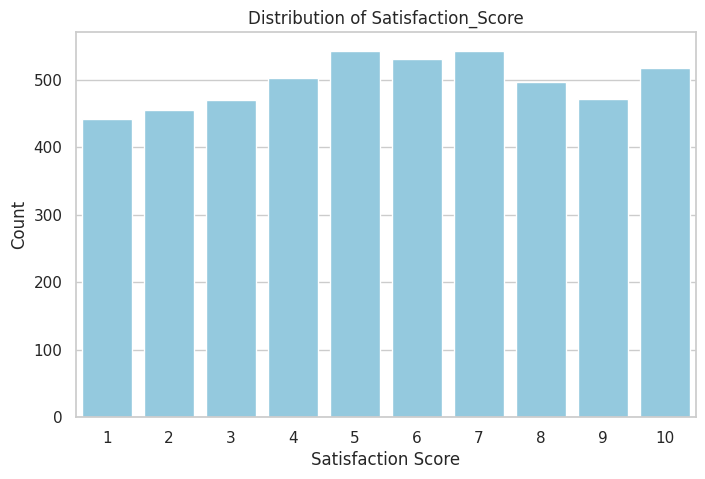

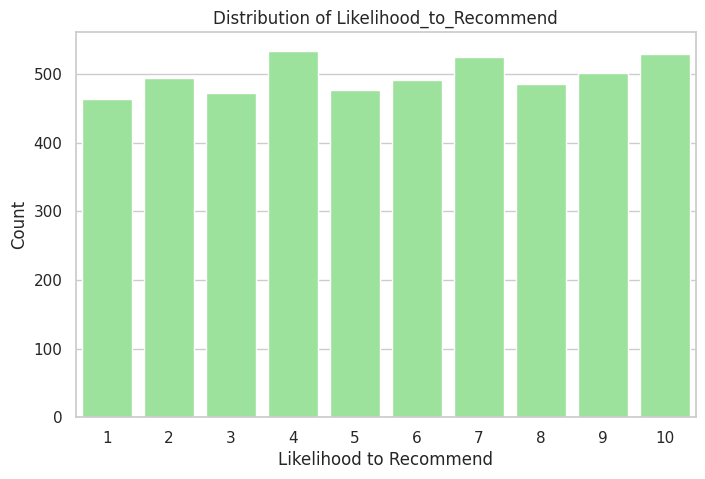

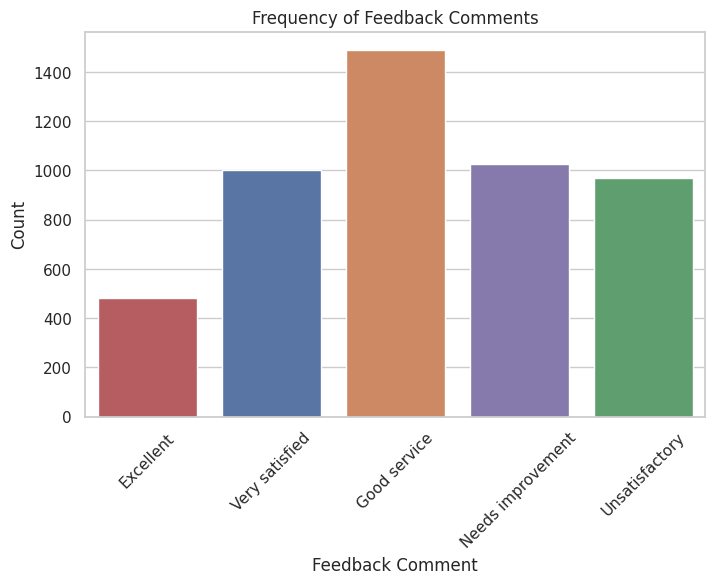

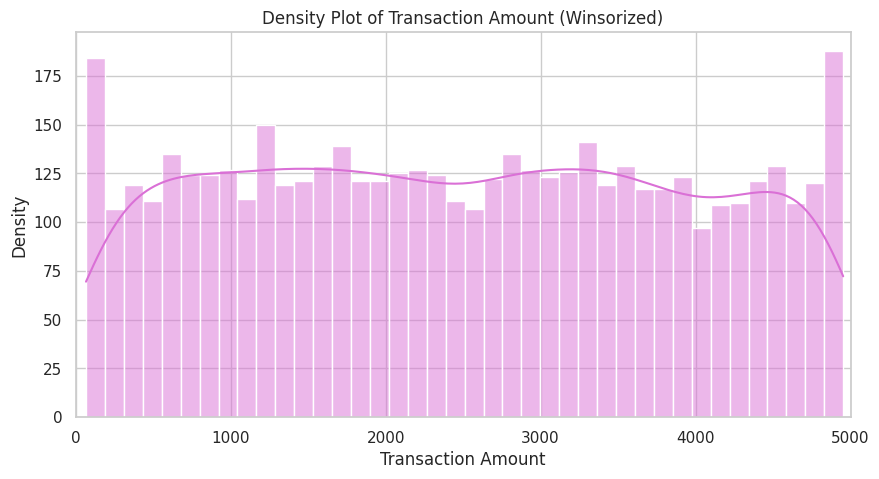

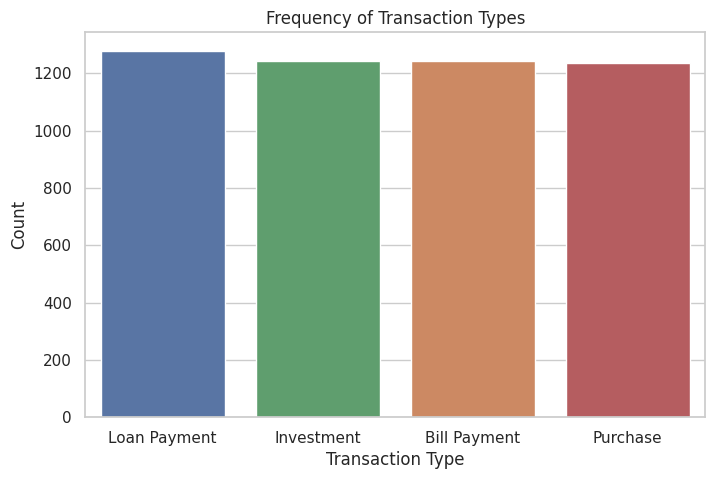


--- Transaction Type Frequency Count ---
Transaction_Type
Loan Payment    1279
Investment      1243
Bill Payment    1241
Purchase        1237
Name: count, dtype: int64


In [ ]:
#Step 13 - Set distribution plots
sns.set(style="whitegrid")

# 1. Satisfaction_Score distribution
plt.figure(figsize=(8,5))
sns.countplot(
    data=stacked_df,
    x='Satisfaction_Score',
    color='skyblue',
    order=range(1, 11)  # Ensures x-axis shows 1-10
)
plt.title('Distribution of Satisfaction_Score')
plt.xlabel('Satisfaction Score')
plt.ylabel('Count')
plt.show()

# 2. Likelihood_to_Recommend distribution as bar chart (x-axis 1-10)
plt.figure(figsize=(8,5))
sns.countplot(
    data=stacked_df,
    x='Likelihood_to_Recommend',
    color='lightgreen',
    order=range(1, 11)  # Ensures x-axis shows 1-10
)
plt.title('Distribution of Likelihood_to_Recommend')
plt.xlabel('Likelihood to Recommend')
plt.ylabel('Count')
plt.show()

# 3. Feedback_Comments frequency (custom order)
feedback_order = ["Excellent", "Very satisfied", "Good service", "Needs improvement", "Unsatisfactory"]
plt.figure(figsize=(8,5))
sns.countplot(
    data=stacked_df,
    x='Feedback_Comments',
    order=feedback_order,
    hue='Feedback_Comments',
    dodge=False
)
plt.title('Frequency of Feedback Comments')
plt.xlabel('Feedback Comment')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend([], [], frameon=False)  # remove legend
plt.show()

# 4. Transaction_Amount distribution histogram (after Winsorization)
transaction_rows = stacked_df['Transaction_ID'].notna()

plt.figure(figsize=(10,5))
sns.histplot(
    stacked_df.loc[transaction_rows, 'Transaction_Amount'],
    bins=40,       # increase bins for more detail
    color='orchid',
    kde=True        # overlay KDE
)
plt.title('Density Plot of Transaction Amount (Winsorized)')
plt.xlabel('Transaction Amount')
plt.ylabel('Density')
plt.xlim(0, 5000)  # max after Winsorization
plt.show()

# 5. Transaction_Type frequency count
plt.figure(figsize=(8,5))
sns.countplot(
    data=stacked_df,
    x='Transaction_Type',
    order=stacked_df['Transaction_Type'].value_counts().index,
    hue='Transaction_Type',
    dodge=False
)
plt.title('Frequency of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.legend([], [], frameon=False)
plt.show()

print("\n--- Transaction Type Frequency Count ---")
print(stacked_df['Transaction_Type'].value_counts())

Feature Engineering Dataset

Feature Engineering Notes:
Aggregations, ratios, and domain-driven transformations were applied to transaction and feedback data. Transaction- and feedback-level data were engineered into customer-level behavioral features, including total and average transaction amounts, transaction type counts and ratios, spending volatility, high-value transaction ratios, satisfaction and loyalty metrics, to support clustering and segmentation.

In [ ]:
#Step 14 - Create Customer Profile Dataset
# --- Unique Customer IDs ---
customer_profile_df = pd.DataFrame({'Customer_ID': stacked_df['Customer_ID'].unique()})

# --- Reset index for cleanliness ---
customer_profile_df = customer_profile_df.sort_values('Customer_ID').reset_index(drop=True)

# --- Display head ---
print("=== Customer Profile Dataset ===")
display(customer_profile_df.head())

=== Customer Profile Dataset ===


,Customer_ID
0,1
1,2
2,3
3,4
4,5


In [ ]:
# Step 15: Calculate total_transaction_amount per Customer_ID
# Purpose: Proxy for financial capacity (how much the customer spends overall)

# --- 1. Aggregate transaction amount for each customer ---
total_txn = stacked_df.groupby('Customer_ID')['Transaction_Amount'].sum(min_count=1).reset_index()
total_txn.rename(columns={'Transaction_Amount': 'total_transaction_amount'}, inplace=True)

# --- 2. Merge into customer_profile_df ---
customer_profile_df = customer_profile_df.merge(total_txn, on='Customer_ID', how='left')

# --- 3. Fill NaN with 0 for customers with no transactions ---
customer_profile_df['total_transaction_amount'] = customer_profile_df['total_transaction_amount'].fillna(0)

# --- Display updated customer profile head ---
print("=== Customer Profile Dataset ===")
display(customer_profile_df.head())

=== Customer Profile Dataset ===


,Customer_ID,total_transaction_amount
0,1,16795.0
1,2,4907.0
2,3,1538.0
3,4,8295.0
4,5,14798.0


In [ ]:
# Step 17 - Calculate avg_transaction_amount per Customer_ID
# Purpose: Serves as a proxy for typical spending behavior of a customer

# --- 1. Group transactions by Customer_ID and compute mean ---
avg_transaction = stacked_df.groupby('Customer_ID')['Transaction_Amount'].mean().reset_index()

# --- 2. Name the new column ---
avg_transaction.rename(columns={'Transaction_Amount': 'avg_transaction_amount'}, inplace=True)

# --- 3. Merge into the Customer Profile Dataset ---
customer_profile_df = customer_profile_df.merge(avg_transaction, on='Customer_ID', how='left')

# --- 4. Fill NaN with 0 for customers with no transactions ---
customer_profile_df['avg_transaction_amount'] = customer_profile_df['avg_transaction_amount'].fillna(0)

# --- 5. Display the first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount
0,1,16795.0,2799.166667
1,2,4907.0,2453.500000
2,3,1538.0,1538.000000
3,4,8295.0,4147.500000
4,5,14798.0,2959.600000


In [ ]:
#Step 16 - Derive income_level from avg_transaction_amount using quartiles
# Purpose: Estimate the customer's financial capacity relative to other customers.
# Using relative quartiles (25th and 75th percentiles) allows us to categorize customers as Low, Medium, or High spenders
# rather than using arbitrary thresholds. This approach adapts to the dataset distribution and avoids bias from extreme outliers.

# --- Compute quartiles ---
q1 = customer_profile_df['avg_transaction_amount'].quantile(0.25)
q3 = customer_profile_df['avg_transaction_amount'].quantile(0.75)

# --- Define function to assign income group ---
def income_group(amount):
    if pd.isna(amount):
        return 'Unknown'
    elif amount <= q1:
        return 'Low'
    elif amount <= q3:
        return 'Medium'
    else:
        return 'High'

# --- Apply function ---
customer_profile_df['income_level'] = customer_profile_df['avg_transaction_amount'].apply(income_group)

# --- Encode as numeric for modeling (Low=0, Medium=1, High=2, Unknown=-1) ---
# Ordinal encoding is selected because the income_level feature has a natural order (Low < Medium < High).
# Mapping 'Low' → 0, 'Medium' → 1, 'High' → 2, and 'Unknown' → -1 preserves this order numerically.
# This allows machine learning models to interpret the relative ranking of income levels while using a numeric representation.
income_mapping = {'Low': 0, 'Medium': 1, 'High': 2, 'Unknown': -1}
customer_profile_df['income_level_encoded'] = customer_profile_df['income_level'].map(income_mapping)

# --- Display updated customer profile head ---
print("=== Customer Profile Dataset ===")
display(customer_profile_df.head())

=== Customer Profile Dataset ===


,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded
0,1,16795.0,2799.166667,Medium,1
1,2,4907.0,2453.500000,Medium,1
2,3,1538.0,1538.000000,Low,0
3,4,8295.0,4147.500000,High,2
4,5,14798.0,2959.600000,High,2


In [ ]:
#Step 18 - Count Bill Payment transactions per Customer_ID
# Purpose: Behavioral indicator → Savings Account preference

# --- 1. Count the transaction type ---
bill_payment_count = stacked_df[stacked_df['Transaction_Type'] == 'Bill Payment'] \
    .groupby('Customer_ID')['Transaction_ID'].count().reset_index()

bill_payment_count.rename(columns={'Transaction_ID': 'bill_payment_count'}, inplace=True)

# --- 2. Merge the new column into Customer Profile Dataset ---
customer_profile_df = customer_profile_df.merge(bill_payment_count, on='Customer_ID', how='left')

# --- 3. Fill NaN with 0 for customers with no bill payments ---
customer_profile_df['bill_payment_count'] = customer_profile_df['bill_payment_count'].fillna(0).astype(int)

# --- 4. Display the first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded,bill_payment_count
0,1,16795.0,2799.166667,Medium,1,3
1,2,4907.0,2453.500000,Medium,1,1
2,3,1538.0,1538.000000,Low,0,1
3,4,8295.0,4147.500000,High,2,0
4,5,14798.0,2959.600000,High,2,2


In [ ]:
#Step 19: Count Loan Payment transactions per Customer_ID
# Purpose: Behavioral indicator → Loan preference

# --- 1. Count the transaction type ---
loan_payment_count = stacked_df[stacked_df['Transaction_Type'] == 'Loan Payment'] \
    .groupby('Customer_ID')['Transaction_ID'].count().reset_index()

loan_payment_count.rename(columns={'Transaction_ID': 'loan_payment_count'}, inplace=True)

# --- 2. Merge the new column into Customer Profile Dataset ---
customer_profile_df = customer_profile_df.merge(loan_payment_count, on='Customer_ID', how='left')

# --- 3. Fill NaN with 0 for customers with no loan payments ---
customer_profile_df['loan_payment_count'] = customer_profile_df['loan_payment_count'].fillna(0).astype(int)

# --- 4. Display the first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded,bill_payment_count,loan_payment_count
0,1,16795.0,2799.166667,Medium,1,3,1
1,2,4907.0,2453.500000,Medium,1,1,1
2,3,1538.0,1538.000000,Low,0,1,0
3,4,8295.0,4147.500000,High,2,0,1
4,5,14798.0,2959.600000,High,2,2,0


In [ ]:
#Step 20: Count Investment transactions per Customer_ID
# Purpose: Behavioral indicator → Investment preference

# --- 1. Count the transaction type ---
investment_count = stacked_df[stacked_df['Transaction_Type'] == 'Investment'] \
    .groupby('Customer_ID')['Transaction_ID'].count().reset_index()

investment_count.rename(columns={'Transaction_ID': 'investment_count'}, inplace=True)

# --- 2. Merge the new column into Customer Profile Dataset ---
customer_profile_df = customer_profile_df.merge(investment_count, on='Customer_ID', how='left')

# --- 3. Fill NaN with 0 for customers with no investment payments ---
customer_profile_df['investment_count'] = customer_profile_df['investment_count'].fillna(0).astype(int)

# --- 4. Display the first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded,bill_payment_count,loan_payment_count,investment_count
0,1,16795.0,2799.166667,Medium,1,3,1,1
1,2,4907.0,2453.500000,Medium,1,1,1,0
2,3,1538.0,1538.000000,Low,0,1,0,0
3,4,8295.0,4147.500000,High,2,0,1,0
4,5,14798.0,2959.600000,High,2,2,0,1


In [ ]:
#Step 21: Count Purchase transactions per Customer_ID
# Purpose: Behavioral indicator → Credit Card preference

# --- 1. Count the transaction type ---
purchase_count = stacked_df[stacked_df['Transaction_Type'] == 'Purchase'] \
    .groupby('Customer_ID')['Transaction_ID'].count().reset_index()

purchase_count.rename(columns={'Transaction_ID': 'purchase_count'}, inplace=True)

# --- 2. Merge the new column into Customer Profile Dataset ---
customer_profile_df = customer_profile_df.merge(purchase_count, on='Customer_ID', how='left')

# --- 3. Fill NaN with 0 for customers with no purchase payments ---
customer_profile_df['purchase_count'] = customer_profile_df['purchase_count'].fillna(0).astype(int)

# --- 4. Display the first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded,bill_payment_count,loan_payment_count,investment_count,purchase_count
0,1,16795.0,2799.166667,Medium,1,3,1,1,1
1,2,4907.0,2453.500000,Medium,1,1,1,0,0
2,3,1538.0,1538.000000,Low,0,1,0,0,0
3,4,8295.0,4147.500000,High,2,0,1,0,1
4,5,14798.0,2959.600000,High,2,2,0,1,2


In [ ]:
#Step 22: Transaction type ratios
# Purpose: Behavioral indicators → product preference / risk profile

# --- 1. Total transactions per customer ---
customer_profile_df['total_transaction_count'] = (
    customer_profile_df['bill_payment_count'] +
    customer_profile_df['loan_payment_count'] +
    customer_profile_df['investment_count'] +
    customer_profile_df['purchase_count']
)

# --- 2. Calculate ratios ---
customer_profile_df['loan_payment_ratio'] = (customer_profile_df['loan_payment_count'] / customer_profile_df['total_transaction_count']).fillna(0)
customer_profile_df['bill_payment_ratio'] = (customer_profile_df['bill_payment_count'] / customer_profile_df['total_transaction_count']).fillna(0)
customer_profile_df['investment_ratio'] = (customer_profile_df['investment_count'] / customer_profile_df['total_transaction_count']).fillna(0)
customer_profile_df['purchase_ratio'] = (customer_profile_df['purchase_count'] / customer_profile_df['total_transaction_count']).fillna(0)

# --- 3. Display the first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded,bill_payment_count,loan_payment_count,investment_count,purchase_count,total_transaction_count,loan_payment_ratio,bill_payment_ratio,investment_ratio,purchase_ratio
0,1,16795.0,2799.166667,Medium,1,3,1,1,1,6,0.166667,0.5,0.166667,0.166667
1,2,4907.0,2453.500000,Medium,1,1,1,0,0,2,0.500000,0.5,0.000000,0.000000
2,3,1538.0,1538.000000,Low,0,1,0,0,0,1,0.000000,1.0,0.000000,0.000000
3,4,8295.0,4147.500000,High,2,0,1,0,1,2,0.500000,0.0,0.000000,0.500000
4,5,14798.0,2959.600000,High,2,2,0,1,2,5,0.000000,0.4,0.200000,0.400000


In [ ]:
#Step 23: Transaction amount volatility and capacity
# Purpose: Measure spending volatility & financial capacity → risk profile input

# --- 1. Calculate values ---
txn_stats = stacked_df.groupby('Customer_ID')['Transaction_Amount'].agg(
    transaction_amount_std='std',
    max_transaction_amount='max',
    min_transaction_amount='min'
).reset_index()

# --- 2. Merge into customer profile dataset ---
customer_profile_df = customer_profile_df.merge(txn_stats, on='Customer_ID', how='left')

# --- 3. Fill NaN for customers with no transactions ---
customer_profile_df[['transaction_amount_std','max_transaction_amount','min_transaction_amount']] = customer_profile_df[
    ['transaction_amount_std','max_transaction_amount','min_transaction_amount']
].fillna(0)

# --- 4. Display the first few rows ---
display(customer_profile_df[['Customer_ID','transaction_amount_std','max_transaction_amount','min_transaction_amount']].head())

,Customer_ID,transaction_amount_std,max_transaction_amount,min_transaction_amount
0,1,2053.664668,4952.0,156.0
1,2,560.735677,2850.0,2057.0
2,3,0.000000,1538.0,1538.0
3,4,832.264681,4736.0,3559.0
4,5,1386.584040,4878.0,1508.0


In [ ]:
# Step 24: High-value transaction ratio (percentile-based)
# Purpose: Indicates engagement with high-value transactions → risk & capacity

# --- 1. Compute the 95th percentile threshold (top 5%) ---
high_value_threshold = stacked_df['Transaction_Amount'].quantile(0.95)
print(f"High-value transaction threshold (top 5%): {high_value_threshold:.2f}")

# --- 2. Count high-value transactions per customer ---
high_value_txn = stacked_df[stacked_df['Transaction_Amount'] > high_value_threshold] \
    .groupby('Customer_ID')['Transaction_ID'].count().reset_index()
high_value_txn.rename(columns={'Transaction_ID': 'high_value_txn_count'}, inplace=True)

# --- 3. Merge into customer profile dataset ---
customer_profile_df = customer_profile_df.merge(high_value_txn, on='Customer_ID', how='left')
customer_profile_df['high_value_txn_count'] = customer_profile_df['high_value_txn_count'].fillna(0)

customer_profile_df['total_transaction_count'] = customer_profile_df['total_transaction_count'].fillna(0)

# --- 4. Calculate ratio ---
customer_profile_df['high_value_txn_ratio'] = ( customer_profile_df['high_value_txn_count'] / customer_profile_df['total_transaction_count'] ).fillna(0)

# --- 5. Display the first few rows ---
display(customer_profile_df[['Customer_ID','high_value_txn_count','high_value_txn_ratio']].head())

High-value transaction threshold (top 5%): 4770.00


,Customer_ID,high_value_txn_count,high_value_txn_ratio
0,1,2,0.333333
1,2,0,0.0
2,3,0,0.0
3,4,0,0.0
4,5,1,0.2


In [ ]:
#Step 25: Analyze customer feedback-based features

# --- 1. Average satisfaction score ---
# Purpose: Overall satisfaction; high score → likely to adopt / stick with high-value products.
avg_satisfaction_score = stacked_df.groupby('Customer_ID')['Satisfaction_Score'].mean().reset_index()
avg_satisfaction_score.rename(columns={'Satisfaction_Score':'avg_satisfaction_score'}, inplace=True)

# --- 2. Engagement count ---
# Purpose: Customer engagement; more feedback = more active/loyal.
engagement_count = stacked_df.groupby('Customer_ID')['Satisfaction_Score'].count().reset_index()
engagement_count.rename(columns={'Satisfaction_Score':'engagement_count'}, inplace=True)

# --- 3. Satisfaction std (volatility) ---
# Purpose: Consistency of satisfaction; high std → unstable behavior → potential risk for high-value products.
satisfaction_std = stacked_df.groupby('Customer_ID')['Satisfaction_Score'].std().reset_index()
satisfaction_std.rename(columns={'Satisfaction_Score':'satisfaction_std'}, inplace=True)

# --- 4️. Average Likelihood to Recommend ---
# Purpose: Loyalty / willingness to promote products; complements satisfaction score.
avg_ltr = stacked_df.groupby('Customer_ID')['Likelihood_to_Recommend'].mean().reset_index()
avg_ltr.rename(columns={'Likelihood_to_Recommend':'avg_ltr'}, inplace=True)

# --- 5. Merge all feedback features into customer_profile_df ---
customer_profile_df = customer_profile_df.merge(avg_satisfaction_score, on='Customer_ID', how='left')
customer_profile_df = customer_profile_df.merge(engagement_count, on='Customer_ID', how='left')
customer_profile_df = customer_profile_df.merge(satisfaction_std, on='Customer_ID', how='left')
customer_profile_df = customer_profile_df.merge(avg_ltr, on='Customer_ID', how='left')

# --- 6. Fill NaN for customers with no feedback ---
customer_profile_df[['avg_satisfaction_score','engagement_count','satisfaction_std','avg_ltr']] = customer_profile_df[
    ['avg_satisfaction_score','engagement_count','satisfaction_std','avg_ltr']
].fillna(0)

# --- 7. Loyalty flag ---
# Purpose: Quick binary indicator for recommending high-value / high-risk products.
customer_profile_df['loyalty_flag'] = (customer_profile_df['avg_satisfaction_score'] >= 8).astype(int)

# --- 8. Display first few rows ---
display(customer_profile_df.head())

,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level,income_level_encoded,bill_payment_count,loan_payment_count,investment_count,purchase_count,total_transaction_count,...,transaction_amount_std,max_transaction_amount,min_transaction_amount,high_value_txn_count,high_value_txn_ratio,avg_satisfaction_score,engagement_count,satisfaction_std,avg_ltr,loyalty_flag
0,1,16795.0,2799.166667,Medium,1,3,1,1,1,6,...,2053.664668,4952.0,156.0,2,0.333333,8.5,2,2.12132,9.0,1
1,2,4907.0,2453.500000,Medium,1,1,1,0,0,2,...,560.735677,2850.0,2057.0,0,0.0,4.333333,3,2.309401,5.0,0
2,3,1538.0,1538.000000,Low,0,1,0,0,0,1,...,0.000000,1538.0,1538.0,0,0.0,8.333333,3,2.081666,3.666667,1
3,4,8295.0,4147.500000,High,2,0,1,0,1,2,...,832.264681,4736.0,3559.0,0,0.0,5.5,6,2.073644,3.333333,0
4,5,14798.0,2959.600000,High,2,2,0,1,2,5,...,1386.584040,4878.0,1508.0,1,0.2,6.444444,9,2.006932,5.666667,0


In [ ]:
# Step 26: Explore the customer profile dataset
# Purpose: Verify the feature statistics and data types after feature engineering.

print("=== Customer Profile Dataset Statistics ===")
display(customer_profile_df.describe())

print("\n=== Customer Profile Dataset Info ===")
display(customer_profile_df.info())

=== Customer Profile Dataset Statistics ===


,Customer_ID,total_transaction_amount,avg_transaction_amount,income_level_encoded,bill_payment_count,loan_payment_count,investment_count,purchase_count,total_transaction_count,loan_payment_ratio,...,transaction_amount_std,max_transaction_amount,min_transaction_amount,high_value_txn_count,high_value_txn_ratio,avg_satisfaction_score,engagement_count,satisfaction_std,avg_ltr,loyalty_flag
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.000000
mean,500.500000,12461.690000,2475.667937,0.999000,1.241000,1.279000,1.24300,1.237000,5.000000,0.246724,...,1265.723026,3985.427000,1009.493000,0.248,<NA>,5.606725,4.969,2.609457,5.574635,0.064000
std,288.819436,6517.096352,802.581975,0.708167,1.160287,1.161253,1.07569,1.063937,2.218315,0.219430,...,531.307036,1003.238319,950.921375,0.496732,<NA>,1.403082,1.978877,0.981029,1.454892,0.244875
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,<NA>,1.0,1.0,0.0,1.0,0.000000
25%,250.750000,7716.500000,1980.500000,0.000000,0.000000,0.000000,0.00000,0.000000,3.000000,0.000000,...,975.730702,3562.500000,319.500000,0.0,<NA>,4.75,4.0,2.073644,4.571429,0.000000
50%,500.500000,11908.500000,2453.125000,1.000000,1.000000,1.000000,1.00000,1.000000,5.000000,0.250000,...,1314.572576,4340.000000,734.500000,0.0,<NA>,5.6,5.0,2.701851,5.666667,0.000000
75%,750.250000,16363.250000,2937.380952,1.250000,2.000000,2.000000,2.00000,2.000000,6.000000,0.381250,...,1622.965236,4732.250000,1366.500000,0.0,<NA>,6.5,6.0,3.265986,6.5,0.000000
max,1000.000000,37281.000000,4952.000000,2.000000,7.000000,7.000000,5.00000,6.000000,13.000000,1.000000,...,3335.422687,4952.000000,4952.000000,3.0,<NA>,10.0,13.0,6.363961,10.0,1.000000



=== Customer Profile Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               1000 non-null   int64  
 1   total_transaction_amount  1000 non-null   float64
 2   avg_transaction_amount    1000 non-null   float64
 3   income_level              1000 non-null   object 
 4   income_level_encoded      1000 non-null   int64  
 5   bill_payment_count        1000 non-null   int64  
 6   loan_payment_count        1000 non-null   int64  
 7   investment_count          1000 non-null   int64  
 8   purchase_count            1000 non-null   int64  
 9   total_transaction_count   1000 non-null   int64  
 10  loan_payment_ratio        1000 non-null   float64
 11  bill_payment_ratio        1000 non-null   float64
 12  investment_ratio          1000 non-null   float64
 13  purchase_ratio           

None

Data Visualization


--- Total Transaction Counts per Income Level ---
                      bill_payment_count  loan_payment_count  \
income_level_encoded                                           
0                                    267                 262   
1                                    685                 709   
2                                    289                 308   

                      investment_count  purchase_count  
income_level_encoded                                    
0                                  288             276  
1                                  670             698  
2                                  285             263  


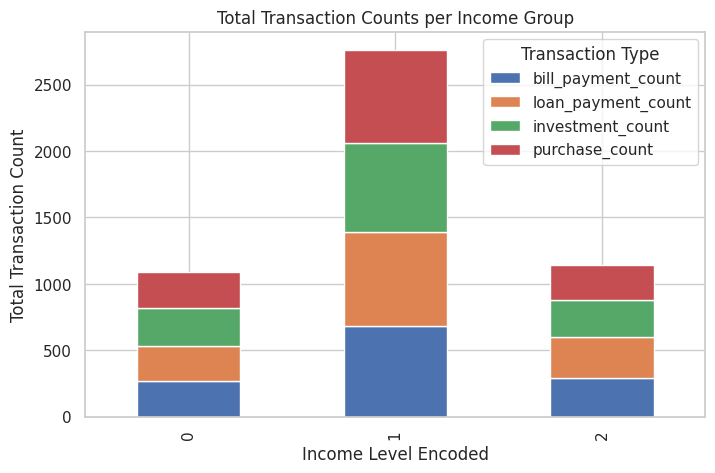


--- Total High-Value Transaction Count by Income Level ---
   income_level_encoded  high_value_txn_count
0                     0                    14
1                     1                   114
2                     2                   120


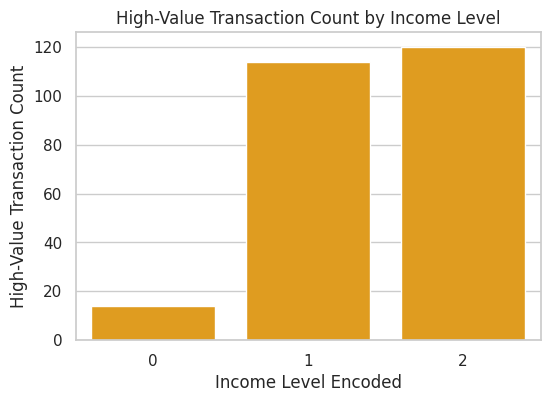

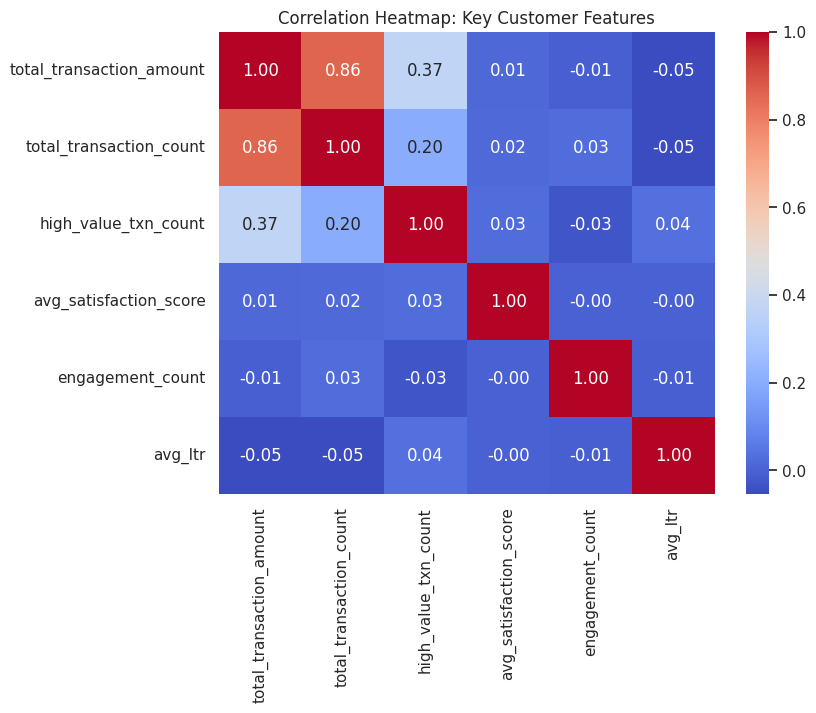

                          total_transaction_amount  total_transaction_count  \
total_transaction_amount                  1.000000                 0.855938   
total_transaction_count                   0.855938                 1.000000   
high_value_txn_count                      0.367245                 0.199854   
avg_satisfaction_score                    0.014730                 0.016701   
engagement_count                         -0.006455                 0.027592   
avg_ltr                                  -0.052390                -0.054082   

                          high_value_txn_count  avg_satisfaction_score  \
total_transaction_amount              0.367245                0.014730   
total_transaction_count               0.199854                0.016701   
high_value_txn_count                  1.000000                0.025712   
avg_satisfaction_score                0.025712                1.000000   
engagement_count                     -0.031886               -0.003539   
av

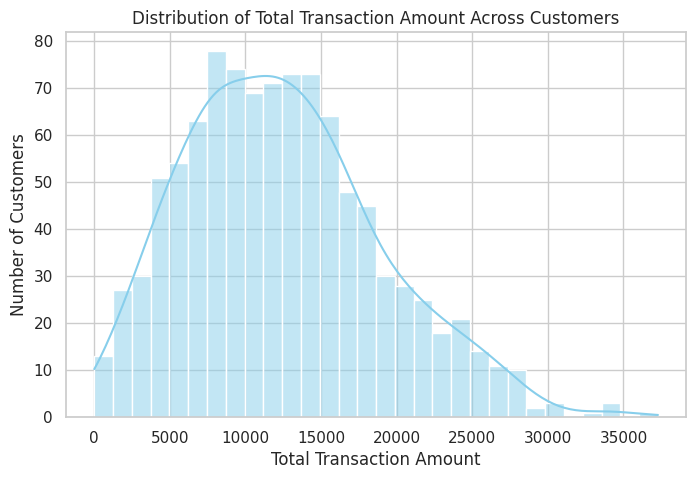


--- Total Transaction Amount Descriptive Stats ---
count     1000.000000
mean     12461.690000
std       6517.096352
min          0.000000
25%       7716.500000
50%      11908.500000
75%      16363.250000
max      37281.000000
Name: total_transaction_amount, dtype: float64


In [ ]:
#Step 27: Data visualization
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10,6)

# 1. Transaction counts per income group
trans_cols = ['bill_payment_count','loan_payment_count','investment_count','purchase_count']

# --- Sum of transaction counts per income group ---
print("\n--- Total Transaction Counts per Income Level ---")
income_grouped_sum = customer_profile_df.groupby('income_level_encoded')[trans_cols].sum()
print(income_grouped_sum)

# --- Prepare stacked bar chart ---
income_grouped_sum.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title("Total Transaction Counts per Income Group")
plt.xlabel("Income Level Encoded")
plt.ylabel("Total Transaction Count")
plt.legend(title='Transaction Type')
plt.show()

# 2. High-value transactions by income group
# Aggregate: sum of high-value transaction counts per income group
hv_count_income = customer_profile_df.groupby('income_level_encoded')['high_value_txn_count'].sum().reset_index()

print("\n--- Total High-Value Transaction Count by Income Level ---")
print(hv_count_income)

# Plot bar chart
plt.figure(figsize=(6,4))
sns.barplot(x='income_level_encoded', y='high_value_txn_count', data=hv_count_income, color="orange")
plt.title("High-Value Transaction Count by Income Level")
plt.xlabel("Income Level Encoded")
plt.ylabel("High-Value Transaction Count")
plt.show()

# 3. Correlation heatmap
# Columns to include
corr_cols = ['total_transaction_amount', 'total_transaction_count',
             'high_value_txn_count', 'avg_satisfaction_score', 'engagement_count', 'avg_ltr']

# Compute correlation
corr_matrix = customer_profile_df[corr_cols].corr()

# Plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap: Key Customer Features")
plt.show()

# Print correlation matrix
print(corr_matrix)

# 4. Histogram of Total Transaction Amount
plt.figure(figsize=(8,5))
sns.histplot(customer_profile_df['total_transaction_amount'], bins=30, kde=True, color='skyblue')
plt.title("Distribution of Total Transaction Amount Across Customers")
plt.xlabel("Total Transaction Amount")
plt.ylabel("Number of Customers")
plt.show()

# Print descriptive stats for interpretation
print("\n--- Total Transaction Amount Descriptive Stats ---")
print(customer_profile_df['total_transaction_amount'].describe())


--- Average Satisfaction Score Statistics ---
count      1000.0
mean     5.606725
std      1.403082
min           1.0
25%          4.75
50%           5.6
75%           6.5
max          10.0
Name: avg_satisfaction_score, dtype: Float64


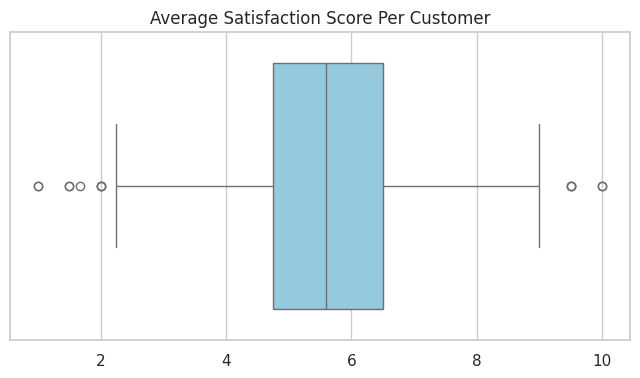

In [ ]:
#Average Satisfaction Score

print("\n--- Average Satisfaction Score Statistics ---")
print(customer_profile_df['avg_satisfaction_score'].describe())

plt.figure(figsize=(8,4))
sns.boxplot(x=customer_profile_df['avg_satisfaction_score'], color='skyblue')

plt.title("Average Satisfaction Score Per Customer")
plt.xlabel("")
plt.show()


--- Engagement Count Frequency ---
engagement_count
1      17
2      78
3     147
4     187
5     208
6     164
7      92
8      56
9      27
10     19
11      3
12      1
13      1
Name: count, dtype: Int64


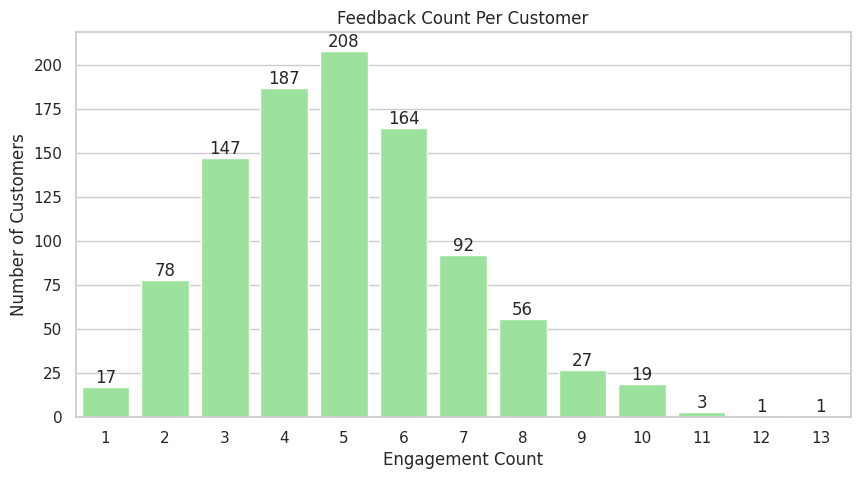

In [ ]:
#Engagement Count
# 1. Print the frequency counts (sorted by the count value, e.g., 1, 2, 3...)
print("\n--- Engagement Count Frequency ---")
print(customer_profile_df['engagement_count'].value_counts().sort_index())

# 2. Plotting the Bar Chart
plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=customer_profile_df,
    x='engagement_count',
    color='lightgreen'
)

# 3. Add numerical labels on top of each bar
for container in ax.containers:
    ax.bar_label(container)

plt.title("Feedback Count Per Customer")
plt.xlabel("Engagement Count")
plt.ylabel("Number of Customers")
plt.show()


--- Average Likelihood to Recommend Statistics ---
count      1000.0
mean     5.574635
std      1.454892
min           1.0
25%      4.571429
50%      5.666667
75%           6.5
max          10.0
Name: avg_ltr, dtype: Float64


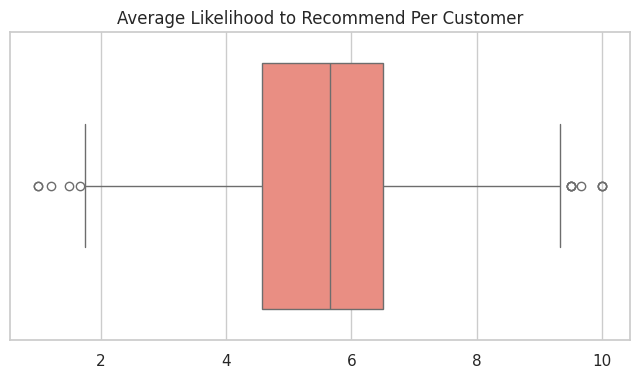

In [ ]:
#Average Likelihood to Recommend (LTR)
print("\n--- Average Likelihood to Recommend Statistics ---")
print(customer_profile_df['avg_ltr'].describe())

plt.figure(figsize=(8,4))
sns.boxplot(x=customer_profile_df['avg_ltr'], color='salmon')

plt.title("Average Likelihood to Recommend Per Customer")
plt.xlabel("")
plt.show()


--- Distribution of Transaction Counts per Customer ---
total_transaction_count
0       7
1      29
2      87
3     145
4     178
5     168
6     139
7     114
8      65
9      40
10     17
11      6
12      3
13      2
Name: count, dtype: int64


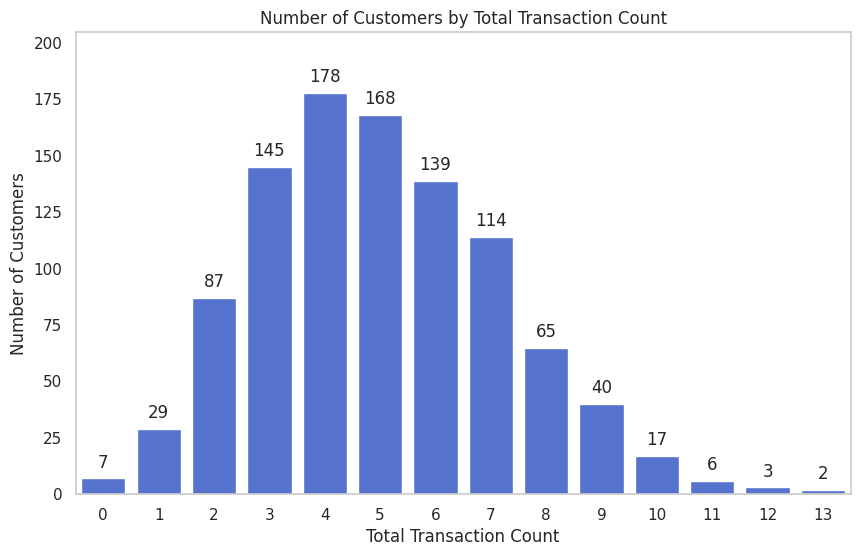

In [ ]:
#Total transaction Count per Customer
# --- 1. Print Numerical Frequency Counts ---
print("\n--- Distribution of Transaction Counts per Customer ---")
# This shows: [Number of transactions] : [Count of customers]
print(customer_profile_df['total_transaction_count'].value_counts().sort_index())

# --- 2. Plotting the Bar Chart ---
plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=customer_profile_df,
    x='total_transaction_count',
    color='royalblue'  # Set the color to a clean blue
)

# --- 3. Add numerical values on top of each bar ---
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Number of Customers by Total Transaction Count")
plt.xlabel("Total Transaction Count")
plt.ylabel("Number of Customers")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
#Step 28: Scale Numeric Features for Clustering ---
# Rationale:
# Numeric features in the dataset (transaction amounts, counts, high-value transaction counts, etc.)
# have different scales. If not scaled, features with larger magnitudes (e.g., total_transaction_amount)
# would dominate distance calculations in clustering. To ensure all features contribute equally,
# Z-score standardization is applied, transforming each feature to zero mean and unit variance.

# --- Select numeric/count features to scale ---
scale_cols = [
    'total_transaction_amount', 'avg_transaction_amount',
    'bill_payment_count', 'loan_payment_count',
    'investment_count', 'purchase_count',
    'total_transaction_count', 'transaction_amount_std',
    'max_transaction_amount', 'min_transaction_amount',
    'high_value_txn_count'
]

# --- Copy dataset to avoid overwriting original data ---
df_scaled = customer_profile_df.copy()

# --- Apply StandardScaler (Z-score scaling) ---
scaler_z = StandardScaler()
df_scaled[scale_cols] = scaler_z.fit_transform(df_scaled[scale_cols])

# --- Print first 5 rows of scaled features for verification ---
print("\n--- Z-score Scaled Features (first 5 rows) ---")
print(df_scaled[scale_cols].head())


--- Z-score Scaled Features (first 5 rows) ---
   total_transaction_amount  avg_transaction_amount  bill_payment_count  \
0                  0.665247                0.403274            1.516763   
1                 -1.159791               -0.027635           -0.207811   
2                 -1.676998               -1.168899           -0.207811   
3                 -0.639668                2.084109           -1.070098   
4                  0.358669                0.603271            0.654476   

   loan_payment_count  investment_count  purchase_count  \
0           -0.240378         -0.226015       -0.222869   
1           -0.240378         -1.156116       -1.163244   
2           -1.101948         -1.156116       -1.163244   
3           -0.240378         -1.156116       -0.222869   
4           -1.101948         -0.226015        0.717506   

   total_transaction_count  transaction_amount_std  max_transaction_amount  \
0                 0.451018                1.483767                0.

In [ ]:
#Step - Save cleaned dataset to Google Drive
# --- Save preprocessed merged data ---
stacked_output_path = '/content/drive/MyDrive/Data Mining Principles/FinMark datasets/Customer_Feedback_and_Transaction_Data_Cleaned.csv'
stacked_df.to_csv(stacked_output_path, index=False)

# --- Save Customer Profile Dataset for Product Recommendation ---
profile_output_path = '/content/drive/MyDrive/Data Mining Principles/FinMark datasets/Customer_Profile_For_Recommendation.csv'
customer_profile_df.to_csv(profile_output_path, index=False)

print("All cleaned datasets have been saved to Google Drive successfully!")

All cleaned datasets have been saved to Google Drive successfully!
